In [63]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [64]:
df=pd.read_csv('../Datasets/deliveries.csv')

In [65]:
pd.unique(df['batting_team'])

array(['Kolkata Knight Riders', 'Royal Challengers Bangalore',
       'Chennai Super Kings', 'Kings XI Punjab', 'Rajasthan Royals',
       'Delhi Daredevils', 'Mumbai Indians', 'Deccan Chargers',
       'Kochi Tuskers Kerala', 'Pune Warriors', 'Sunrisers Hyderabad',
       'Rising Pune Supergiants', 'Gujarat Lions',
       'Rising Pune Supergiant', 'Delhi Capitals', 'Punjab Kings',
       'Lucknow Super Giants', 'Gujarat Titans',
       'Royal Challengers Bengaluru'], dtype=object)

In [66]:
df['batting_team']=df['batting_team'].apply(lambda x: 'Rising Pune Supergiants' if x=='Rising Pune Supergiant' else x)
df['batting_team']=df['batting_team'].apply(lambda x: 'Punjab Kings' if x=='Kings XI Punjab' else x)
df['batting_team']=df['batting_team'].apply(lambda x: 'Royal Challengers Bangalore' if x=='Royal Challengers Bengaluru' else x)
df['bowling_team']=df['bowling_team'].apply(lambda x: 'Rising Pune Supergiants' if x=='Rising Pune Supergiant' else x)
df['bowling_team']=df['bowling_team'].apply(lambda x: 'Punjab Kings' if x=='Kings XI Punjab' else x)
df['bowling_team']=df['bowling_team'].apply(lambda x: 'Royal Challengers Bangalore' if x=='Royal Challengers Bengaluru' else x)

In [67]:
df['over'].value_counts()

over
0     13906
1     13773
2     13597
3     13575
4     13560
5     13494
6     13452
7     13430
8     13396
9     13354
10    13289
11    13261
12    13222
13    13124
14    13024
15    12879
16    12685
17    12318
18    11583
19     9998
Name: count, dtype: int64

In [68]:
df.head(5)

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


In [69]:
df1=df.groupby('batting_team')['total_runs'].sum().reset_index(name='TotalRuns')

In [70]:
df1

,batting_team,TotalRuns
0,Chennai Super Kings,38629
1,Deccan Chargers,11463
2,Delhi Capitals,14900
3,Delhi Daredevils,24296
4,Gujarat Lions,4862
5,Gujarat Titans,7757
6,Kochi Tuskers Kerala,1901
7,Kolkata Knight Riders,39331
8,Lucknow Super Giants,7510
9,Mumbai Indians,42176


C:\Users\Samarth\AppData\Local\Temp\ipykernel_8492\2158172644.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df1,x='batting_team',y='TotalRuns',palette='viridis')


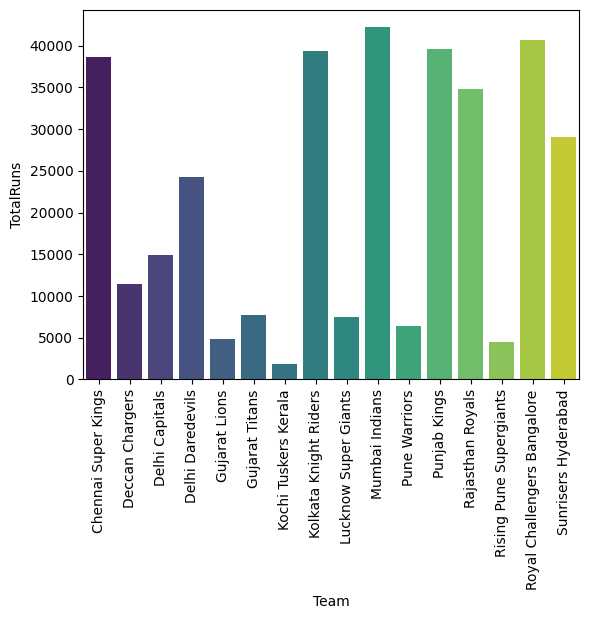

In [71]:
sns.barplot(data=df1,x='batting_team',y='TotalRuns',palette='viridis')
plt.xlabel('Team')
plt.xticks(rotation=90)
plt.show()

In [72]:
df2=df.groupby('batter')['batsman_runs'].sum().reset_index(name='Runs')

In [73]:
df2=df2.sort_values(by='Runs',ascending=False)

In [74]:
df2

,batter,Runs
631,V Kohli,8014
512,S Dhawan,6769
477,RG Sharma,6630
147,DA Warner,6567
546,SK Raina,5536
...,...,...
254,JL Denly,0
400,ND Doshi,0
118,C Nanda,0
667,Yash Dayal,0


In [75]:
df3=df2.head(10)

C:\Users\Samarth\AppData\Local\Temp\ipykernel_8492\827308107.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='batter',y='Runs',data=df3,palette='viridis')


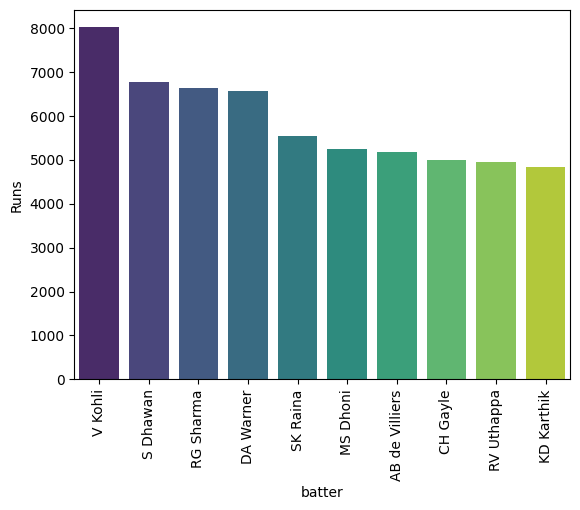

In [76]:
sns.barplot(x='batter',y='Runs',data=df3,palette='viridis')
plt.xticks(rotation=90)
plt.show()

In [77]:
pd.unique(df['dismissal_kind'])

array([nan, 'caught', 'bowled', 'run out', 'lbw', 'retired hurt',
       'stumped', 'caught and bowled', 'hit wicket',
       'obstructing the field', 'retired out'], dtype=object)

In [78]:
df['dismissal_kind']=df['dismissal_kind'].apply(lambda x: 'retired' if( x=='retired out') |(x=='retired hurt') else x)

In [79]:
pd.unique(df['dismissal_kind'])

array([nan, 'caught', 'bowled', 'run out', 'lbw', 'retired', 'stumped',
       'caught and bowled', 'hit wicket', 'obstructing the field'],
      dtype=object)

In [80]:
df['WicketCount']=df['dismissal_kind'].apply(lambda x: 0  if(pd.isna(x)) | (x=='run out') | (x=='retired') | (x=='obstructing the field') else 1)

In [81]:
df

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder,WicketCount
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN,0
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN,0
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN,0
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN,0
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
260915,1426312,2,Kolkata Knight Riders,Sunrisers Hyderabad,9,5,SS Iyer,AK Markram,VR Iyer,1,0,1,NaN,0,NaN,NaN,NaN,0
260916,1426312,2,Kolkata Knight Riders,Sunrisers Hyderabad,9,6,VR Iyer,AK Markram,SS Iyer,1,0,1,NaN,0,NaN,NaN,NaN,0
260917,1426312,2,Kolkata Knight Riders,Sunrisers Hyderabad,10,1,VR Iyer,Shahbaz Ahmed,SS Iyer,1,0,1,NaN,0,NaN,NaN,NaN,0
260918,1426312,2,Kolkata Knight Riders,Sunrisers Hyderabad,10,2,SS Iyer,Shahbaz Ahmed,VR Iyer,1,0,1,NaN,0,NaN,NaN,NaN,0


In [82]:
df4=df.groupby('bowler')['WicketCount'].sum().reset_index(name='TotalWickets')

In [83]:
df4

,bowler,TotalWickets
0,A Ashish Reddy,18
1,A Badoni,2
2,A Chandila,11
3,A Choudhary,5
4,A Dananjaya,0
...,...,...
525,Yash Dayal,28
526,Yash Thakur,24
527,Yudhvir Singh,4
528,Yuvraj Singh,36


In [84]:
df4=df4.sort_values(by='TotalWickets',ascending=False)

In [85]:
df4

,bowler,TotalWickets
524,YS Chahal,205
348,PP Chawla,192
119,DJ Bravo,183
71,B Kumar,181
446,SP Narine,180
...,...,...
48,AUK Pathan,0
26,AC Voges,0
19,AA Kazi,0
508,VS Yeligati,0


In [86]:
df5=df4.head(10)

C:\Users\Samarth\AppData\Local\Temp\ipykernel_8492\1304935970.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df5,x='bowler',y='TotalWickets',palette='viridis')


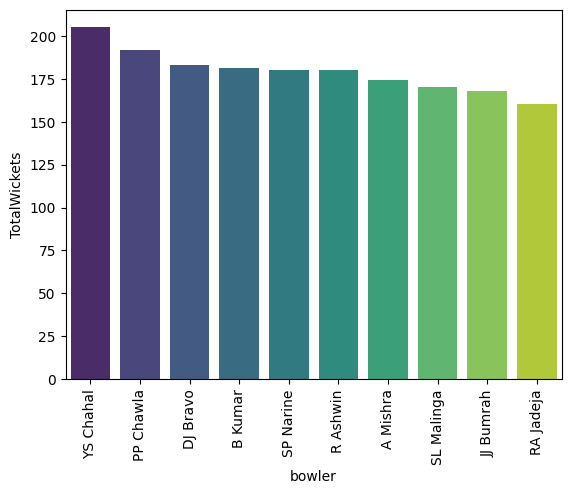

In [87]:
sns.barplot(data=df5,x='bowler',y='TotalWickets',palette='viridis')
plt.xticks(rotation=90)
plt.show()

In [88]:
df6=df.groupby('bowling_team')['extra_runs'].sum().reset_index(name='TotalExtras')

C:\Users\Samarth\AppData\Local\Temp\ipykernel_8492\468150144.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='bowling_team',y='TotalExtras',data=df6,palette='viridis')


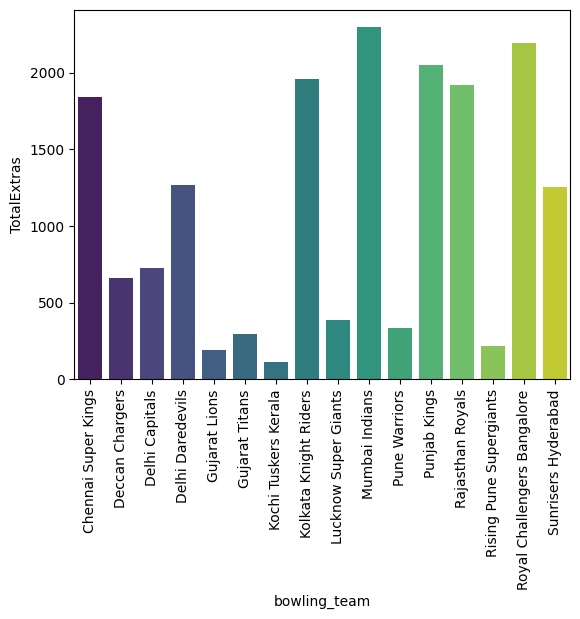

In [89]:
sns.barplot(x='bowling_team',y='TotalExtras',data=df6,palette='viridis')
plt.xticks(rotation=90)
plt.show()

In [90]:
d1=df[df['dismissal_kind']=='run out']

In [91]:
d2=d1.groupby('batter')['is_wicket'].count().reset_index(name='count')

In [92]:
d2

,batter,count
0,A Ashish Reddy,2
1,A Badoni,3
2,A Chandila,1
3,A Chopra,1
4,A Choudhary,1
...,...,...
343,YK Pathan,12
344,YS Chahal,1
345,Yudhvir Singh,1
346,Yuvraj Singh,4


In [93]:
d3=d2.sort_values(by='count',ascending=False)

In [94]:
d3

,batter,count
186,MS Dhoni,25
247,RG Sharma,20
136,KD Karthik,20
329,V Kohli,20
266,S Dhawan,16
...,...,...
4,A Choudhary,1
344,YS Chahal,1
345,Yudhvir Singh,1
3,A Chopra,1


In [95]:
d3=d3.head(10)

C:\Users\Samarth\AppData\Local\Temp\ipykernel_8492\3921138051.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='batter',y='count',data=d3,palette='viridis')


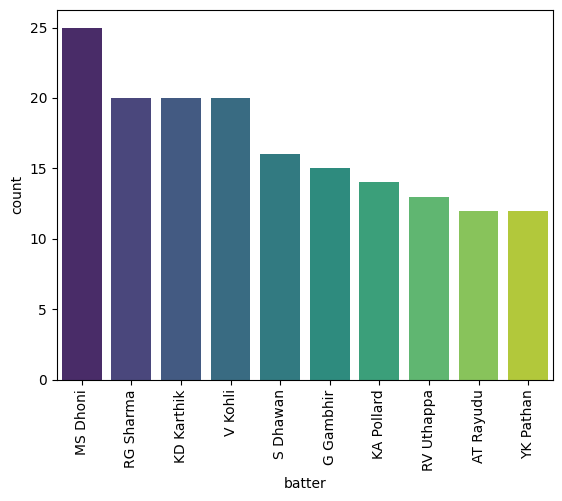

In [96]:
sns.barplot(x='batter',y='count',data=d3,palette='viridis')
plt.xticks(rotation=90)
plt.show()

In [97]:
d5=df['dismissal_kind'].value_counts().reset_index(name='count')

In [98]:
d5

,dismissal_kind,count
0,caught,8063
1,bowled,2212
2,run out,1114
3,lbw,800
4,caught and bowled,367
5,stumped,358
6,retired,18
7,hit wicket,15
8,obstructing the field,3


C:\Users\Samarth\AppData\Local\Temp\ipykernel_8492\3536265722.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=d5,x='dismissal_kind',y='count',palette='viridis')


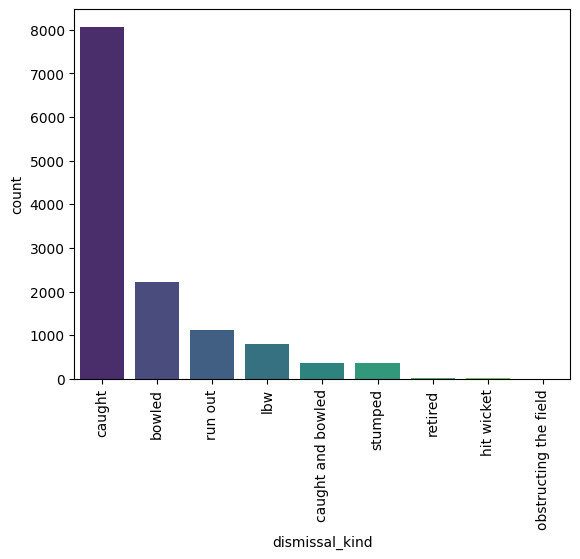

In [99]:
sns.barplot(data=d5,x='dismissal_kind',y='count',palette='viridis')
plt.xticks(rotation=90)
plt.show()

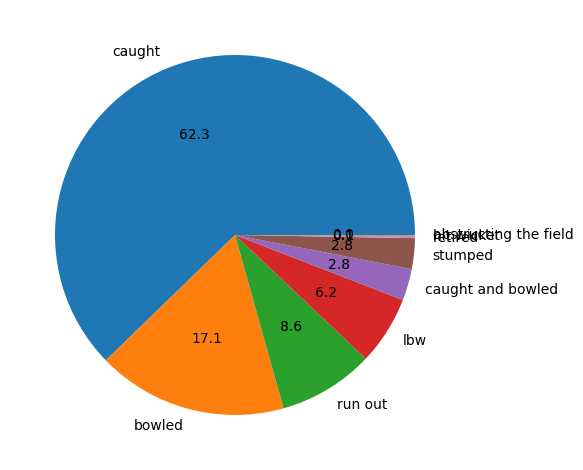

In [100]:
plt.pie(d5['count'],labels=d5['dismissal_kind'],autopct="%1.1f")
plt.tight_layout()
plt.show()

In [101]:
sixes=df[df['batsman_runs']==6]
fours=df[df['batsman_runs']==4]

In [102]:
d8=fours.groupby('batter')['batsman_runs'].count().reset_index(name='TotalFours')
d9=sixes.groupby('batter')['batsman_runs'].count().reset_index(name='TotalSixes')

In [103]:
d8=d8.head(10)

In [104]:
d9=d9.head(10)

C:\Users\Samarth\AppData\Local\Temp\ipykernel_8492\3741725064.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='batter',y='TotalFours',ax=ax[0],data=d8,palette='viridis')
C:\Users\Samarth\AppData\Local\Temp\ipykernel_8492\3741725064.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='batter',y='TotalSixes',ax=ax[1],data=d9,palette='viridis')


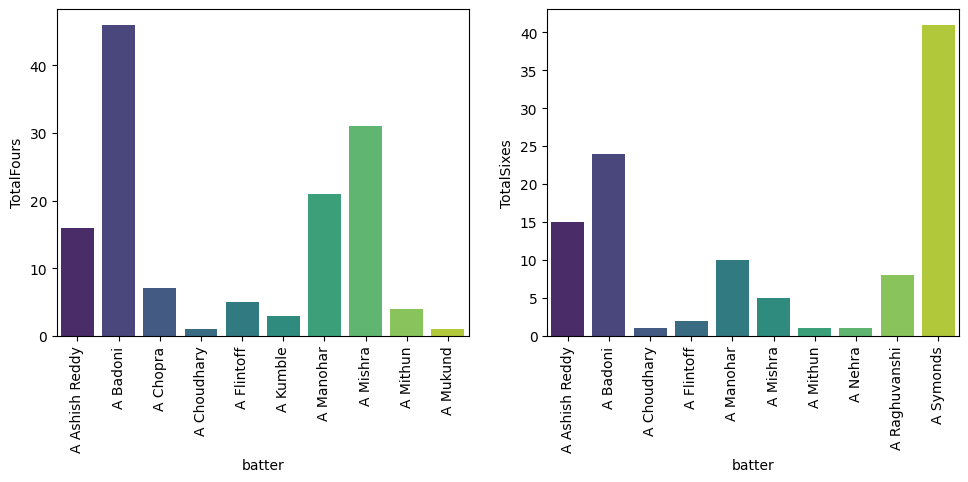

In [105]:
fig,ax=plt.subplots(1,2,figsize=(10,4))
sns.barplot(x='batter',y='TotalFours',ax=ax[0],data=d8,palette='viridis')
sns.barplot(x='batter',y='TotalSixes',ax=ax[1],data=d9,palette='viridis')
plt.tight_layout()
ax[0].tick_params(axis='x',rotation=90)
ax[1].tick_params(axis='x',rotation=90)
plt.show()

In [106]:
df1=df.groupby('bowler')['extra_runs'].sum().reset_index(name='TotalExtras')

In [107]:
df2=df1.sort_values(by='TotalExtras',ascending=False)

In [108]:
df3=df2.head(10)

C:\Users\Samarth\AppData\Local\Temp\ipykernel_8492\2228905497.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='bowler',y='TotalExtras',data=df3,palette='viridis')


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'B Kumar'),
  Text(1, 0, 'SL Malinga'),
  Text(2, 0, 'DJ Bravo'),
  Text(3, 0, 'UT Yadav'),
  Text(4, 0, 'R Ashwin'),
  Text(5, 0, 'P Kumar'),
  Text(6, 0, 'I Sharma'),
  Text(7, 0, 'JJ Bumrah'),
  Text(8, 0, 'Mohammed Siraj'),
  Text(9, 0, 'HV Patel')])

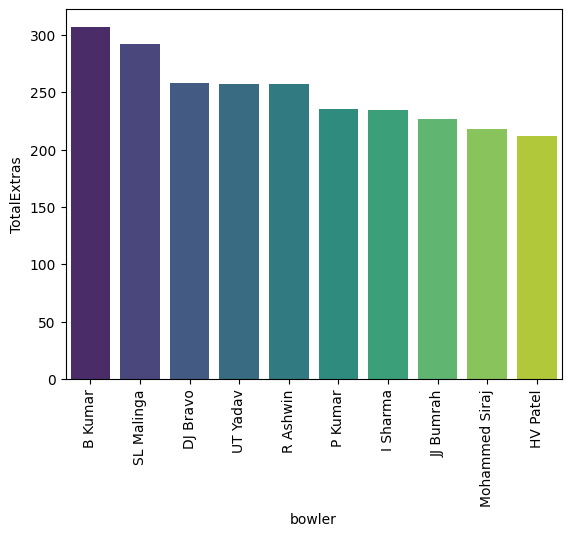

In [109]:
sns.barplot(x='bowler',y='TotalExtras',data=df3,palette='viridis')
plt.xticks(rotation=90)

In [110]:
df['over']=df['over']+1

In [111]:
df.head(10)

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder,WicketCount
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,1,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN,0
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,1,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN,0
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,1,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN,0
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,1,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN,0
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,1,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN,0
5,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,1,6,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN,0
6,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,1,7,BB McCullum,P Kumar,SC Ganguly,0,1,1,legbyes,0,NaN,NaN,NaN,0
7,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,2,1,BB McCullum,Z Khan,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN,0
8,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,2,2,BB McCullum,Z Khan,SC Ganguly,4,0,4,NaN,0,NaN,NaN,NaN,0
9,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,2,3,BB McCullum,Z Khan,SC Ganguly,4,0,4,NaN,0,NaN,NaN,NaN,0


In [112]:
df3=df.groupby('over')['total_runs'].sum().reset_index(name="TotalRuns")

In [113]:
d1=(df['over'].value_counts())/6

In [114]:
d1

over
1     2317.666667
2     2295.500000
3     2266.166667
4     2262.500000
5     2260.000000
6     2249.000000
7     2242.000000
8     2238.333333
9     2232.666667
10    2225.666667
11    2214.833333
12    2210.166667
13    2203.666667
14    2187.333333
15    2170.666667
16    2146.500000
17    2114.166667
18    2053.000000
19    1930.500000
20    1666.333333
Name: count, dtype: float64

In [115]:
df3

,over,TotalRuns
0,1,13651
1,2,16163
2,3,17895
3,4,18415
4,5,18565
5,6,18528
6,7,14839
7,8,15981
8,9,16639
9,10,16353


In [116]:
df4=df3.merge(d1,on='over')

In [117]:
df4

,over,TotalRuns,count
0,1,13651,2317.666667
1,2,16163,2295.500000
2,3,17895,2266.166667
3,4,18415,2262.500000
4,5,18565,2260.000000
5,6,18528,2249.000000
6,7,14839,2242.000000
7,8,15981,2238.333333
8,9,16639,2232.666667
9,10,16353,2225.666667


In [118]:
df4.rename(columns={'count':'noOfOvers'},inplace=True)

In [119]:
df4['AvgRunRate']=df4['TotalRuns']/df4['noOfOvers']

In [120]:
df4

,over,TotalRuns,noOfOvers,AvgRunRate
0,1,13651,2317.666667,5.889976
1,2,16163,2295.500000,7.041168
2,3,17895,2266.166667,7.896595
3,4,18415,2262.500000,8.139227
4,5,18565,2260.000000,8.214602
5,6,18528,2249.000000,8.238328
6,7,14839,2242.000000,6.618644
7,8,15981,2238.333333,7.139687
8,9,16639,2232.666667,7.452523
9,10,16353,2225.666667,7.347461


In [121]:
display(df4.sort_values(by='AvgRunRate',ascending=False))

,over,TotalRuns,noOfOvers,AvgRunRate
19,20,17765,1666.333333,10.661132
18,19,19076,1930.500000,9.881378
17,18,19559,2053.000000,9.527034
16,17,19012,2114.166667,8.992669
15,16,18472,2146.500000,8.605637
14,15,18149,2170.666667,8.361026
5,6,18528,2249.000000,8.238328
4,5,18565,2260.000000,8.214602
3,4,18415,2262.500000,8.139227
13,14,17634,2187.333333,8.061871


In [122]:
df9=df[df['over']<=6]

In [123]:
df10=df9.groupby('batting_team')['total_runs'].sum().reset_index(name='TotalRuns')

In [124]:
df10

,batting_team,TotalRuns
0,Chennai Super Kings,10991
1,Deccan Chargers,3417
2,Delhi Capitals,4709
3,Delhi Daredevils,7360
4,Gujarat Lions,1559
5,Gujarat Titans,2184
6,Kochi Tuskers Kerala,680
7,Kolkata Knight Riders,11941
8,Lucknow Super Giants,2080
9,Mumbai Indians,12225


C:\Users\Samarth\AppData\Local\Temp\ipykernel_8492\3818002727.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='batting_team',y='TotalRuns',data=df10,palette='viridis')


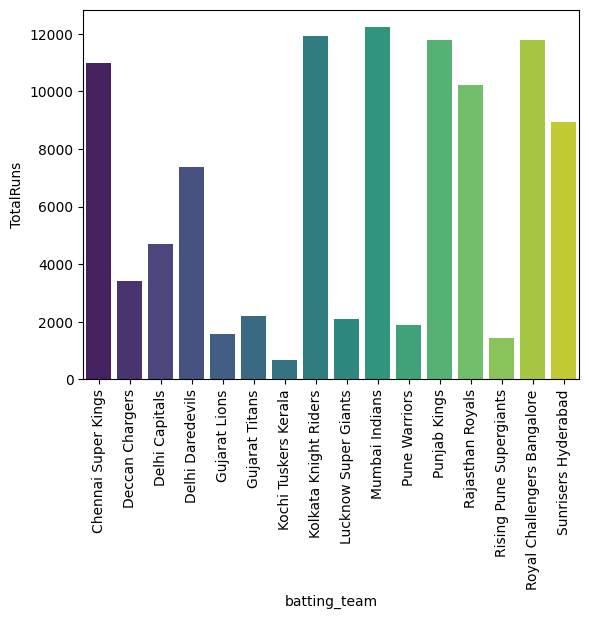

In [126]:
sns.barplot(x='batting_team',y='TotalRuns',data=df10,palette='viridis')
plt.xticks(rotation=90)
plt.show()